In [3]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split

In [7]:
import pandas as pd
import numpy as np

np.random.seed(42)

n_users = 50
n_rows = 1000

df = pd.DataFrame({
    "user_id": np.random.randint(1, n_users + 1, size=n_rows),
    "timestamp": pd.date_range(
        start="2025-01-01",
        periods=n_rows,
        freq="H"
    ),
    "amount": np.round(np.random.exponential(scale=100, size=n_rows), 2),
    "is_fraud": np.random.choice([0, 1], size=n_rows, p=[0.95, 0.05])
})



/var/folders/b9/w_8jnxmx7sl3mh7q1dm9rk940000gp/T/ipykernel_5559/2723529865.py:11: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  "timestamp": pd.date_range(


In [9]:
df.sort_values(by="timestamp", inplace=True)

In [10]:
df.head()

,user_id,timestamp,amount,is_fraud
0,39,2025-01-01 00:00:00,271.34,0
1,29,2025-01-01 01:00:00,0.76,0
2,15,2025-01-01 02:00:00,25.53,0
3,43,2025-01-01 03:00:00,45.47,0
4,8,2025-01-01 04:00:00,66.91,0


In [ ]:
df['total_per_user'] = df.groupby('user_id')['amount'].transform('sum')

In [19]:
df['num_transactions'] = df.groupby('user_id')['amount'].transform('count')

In [20]:
df

,user_id,timestamp,amount,is_fraud,total_per_user,num_transactions
0,39,2025-01-01 00:00:00,271.34,0,2126.63,25
1,29,2025-01-01 01:00:00,0.76,0,1496.17,19
2,15,2025-01-01 02:00:00,25.53,0,1286.89,16
3,43,2025-01-01 03:00:00,45.47,0,1050.02,11
4,8,2025-01-01 04:00:00,66.91,0,1887.26,22
...,...,...,...,...,...,...
995,26,2025-02-11 11:00:00,174.46,0,3267.44,30
996,34,2025-02-11 12:00:00,32.81,0,1769.90,18
997,45,2025-02-11 13:00:00,285.40,0,2374.58,24
998,6,2025-02-11 14:00:00,206.62,0,1462.50,17


In [25]:
df['is_fraud'].value_counts()

is_fraud
0    951
1     49
Name: count, dtype: int64

In [26]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score, precision_score, recall_score

In [31]:
# train test val split based on time

train_size = 0.7
test_size = 0.15
val_size = 0.15

train_data = df.iloc[:int(len(df) * train_size)]
test_data = df.iloc[int(len(df) * train_size):int(len(df) * (train_size + test_size))]
val_data = df.iloc[int(len(df) * (train_size + test_size)):]

x_train = train_data[['amount', 'total_per_user', 'num_transactions']]
y_train = train_data['is_fraud']

x_test = test_data[['amount', 'total_per_user', 'num_transactions']]
y_test = test_data['is_fraud']

In [29]:
lg_model = LogisticRegression()
lg_model.fit(X=x_train, y=y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [46]:
y_pred_proba = lg_model.predict_proba(x_test)[:,1]
y_pred = y_pred_proba >= 0.045

In [47]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.75      0.04      0.08       142
           1       0.04      0.75      0.08         8

    accuracy                           0.08       150
   macro avg       0.40      0.40      0.08       150
weighted avg       0.71      0.08      0.08       150



In [49]:
print(confusion_matrix(y_test, y_pred))
print(f"F1 Score: {f1_score(y_test, y_pred)}")
print(f"Accuracy: {accuracy_score(y_test, y_pred)}")
print(f"Precision: {precision_score(y_test, y_pred)}")
print(f"Recall: {recall_score(y_test, y_pred)}")

[[  6 136]
 [  2   6]]
F1 Score: 0.08
Accuracy: 0.08
Precision: 0.04225352112676056
Recall: 0.75


# USING PIPELINE

In [51]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

In [52]:
pipeline = Pipeline(
    [
        "scaler", StandardScaler(),
        "logistic_regression", LogisticRegression(
            class_weight='balanced',
            random_state=42
        )
    ]
)

In [54]:
x_train

,amount,total_per_user,num_transactions
0,271.34,2126.63,25
1,0.76,1496.17,19
2,25.53,1286.89,16
3,45.47,1050.02,11
4,66.91,1887.26,22
...,...,...,...
695,106.42,1525.18,17
696,484.51,3760.22,29
697,33.39,1783.38,27
698,44.50,2343.10,24


In [57]:
pipeline.fit(
    x_train,
    y_train,
    model__early_stopping_rounds=30,
    model__eval_metric="logloss"
)


ValueError: too many values to unpack (expected 2)

In [56]:
pipeline.predict_proba(X=x_test)[:,1]>=0.05

AttributeError: This 'Pipeline' has no attribute 'predict_proba'

# USING LGBM

In [63]:
from sklearn.datasets import load_iris

In [76]:
df = load_diabetes(as_frame=True)

In [77]:
df = df.frame

In [88]:
df

train_data,test_data = train_test_split(df, test_size = 0.2, random_state=42)

In [90]:
features = ["age", "sex", "bmi", "bp", "s1", "s2", "s3", "s4", "s5", "s6"]

In [93]:
!pip install matplotlib

  Using cached contourpy-1.3.3-cp312-cp312-macosx_11_0_arm64.whl.metadata (5.5 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached kiwisolver-1.4.9-cp312-cp312-macosx_11_0_arm64.whl.metadata (6.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.1/8.1 MB 2.9 MB/s  0:00:02 eta 0:00:01
Using cached contourpy-1.3.3-cp312-cp312-macosx_11_0_arm64.whl (273 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 3.0 MB/s  0:00:00 eta 0:00:01
Using cached kiwisolver-1.4.9-cp312-cp312-macosx_11_0_arm64.whl (64 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [matplotlib]6 [matplotlib]

[notice] A new release of pip is available: 25.2 -> 25.3
[notice] To update, run: pip install --upgrade pip


In [94]:
from matplotlib import pyplot as plt

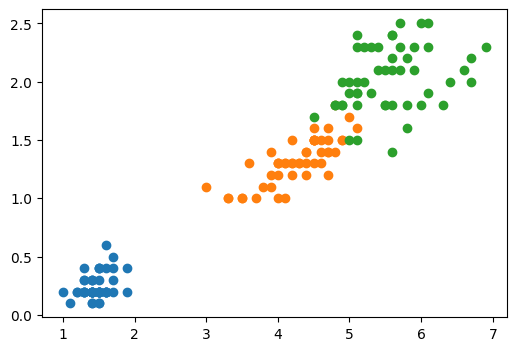

In [97]:

iris = load_iris()
X = iris.data
y = iris.target
names = iris.target_names

plt.figure(figsize=(6, 4))

for i in range(3):
    plt.scatter(
        X[y == i, 2],   # petal length
        X[y == i, 3],   # petal width
        label=names[i]
    )


In [91]:
x_train = train_data[features]
y_train = train_data["target"]

x_test = test_data[features]
y_test = test_data["target"]